In [1]:
from matplotlib import colors
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# nice plotting function with cartopy and coastlines. Use robinson projection
import cartopy.crs as ccrs
import cartopy.feature as cf
import matplotlib.pyplot as plt
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.ticker import FixedLocator

# truncate a colormap. eg, lower half of a diverging cmap
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

# convert a continous cmap to a graduated discrete cmap with n discrete colors. eg, 5 discrete colors from a continuous cmap
def discrete_colormap(cmap, n):
    cmap = plt.get_cmap(cmap)
    new_cmap = colors.ListedColormap(
        cmap(np.linspace(0, 1, n)))
    return new_cmap

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none' # to keep text as text in svg output

# write your plotting code below

def plot_map(dataarray, title='', cmap='viridis', cmap_split = '', discrete_cmap=0, vmin=None, vmax=None, borders=False, norm=None, cbar_label= '', cbar_loc = 'bottom', svg=False, grid_labels=False, local_map=False):
    
    if cmap_split=='low':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.0, 0.5)
    elif cmap_split=='high':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.5, 1.0)
    elif cmap_split=='trim':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.1, 0.9)
    else:
        custom_cmap = plt.get_cmap(cmap)

    if discrete_cmap != 0:
        custom_cmap = discrete_colormap(custom_cmap, discrete_cmap)

    if cbar_label=='':
        cbar_label = dataarray.name
        
    plt.figure(figsize=(12, 8))
    if local_map == False:
        ax = plt.axes(projection=ccrs.Robinson())
    else: # for local maps use PlateCarree projection
        ax = plt.axes(projection=ccrs.PlateCarree())
    # plot only nans in grey. supress cbar
    xr.where(dataarray.isnull(), 1, np.nan).plot(ax=ax, cmap=colors.ListedColormap(['lightgrey']), vmin=1, vmax=1, transform=ccrs.PlateCarree(), add_colorbar=False)
    # plot data
    dataarray.plot(ax=ax, cmap=custom_cmap, vmin=vmin, vmax=vmax, norm=norm, cbar_kwargs={'label': cbar_label, 'location': cbar_loc, 'fraction': 0.05, 'pad': 0.05}, transform=ccrs.PlateCarree())    
    ax.coastlines() # coastlines for context
    # make oceans white. draw it over the data
    ax.add_feature(cf.OCEAN, facecolor='white', zorder=5)
    if borders: # country borders toggle
        ax.add_feature(cf.BORDERS)

    if grid_labels:
        # show only major longitude/latitude labels using gridlines
        lon_ticks = [-180, -120, -60, 0, 60, 120, 180]
        lat_ticks = [-45, -30, -15, 0, 15, 30, 45]

        gl = ax.gridlines(
            crs=ccrs.PlateCarree(),
            draw_labels=True,
            linewidth=0,
            x_inline=False,
            y_inline=False,
        )
        # show only bottom and left labels
        gl.top_labels = False
        gl.right_labels = False
        gl.bottom_labels = True
        gl.left_labels = True
        gl.xlocator = FixedLocator(lon_ticks)
        gl.ylocator = FixedLocator(lat_ticks)
        gl.xformatter = LongitudeFormatter()
        gl.yformatter = LatitudeFormatter()
        gl.xlabel_style = {'size': 10}
        gl.ylabel_style = {'size': 10}

    ax.set_title(title)
    if svg:
        plt.savefig("../export/map_{}.svg".format(dataarray.name), format='svg', bbox_inches='tight')
    plt.show()

# function for calculating global mean and std of a given dataarray, both weighted and unweighted
# weight by grid cell area calculated using earth's radius and latitude. i.e. create a weight array with same lat and lon dimensions as da, where weights = cos(lat) and then use xarray's weighted function to calculate mean and std
# area = R * (max_lat - min_lat) * (max_lon - min_lon) * cos(lat) where R is Earth's radius and lat is the latitude of the grid cell in radians.
# Since we are only interested in relative weights, we can ignore the constant R and the lat/lon differences and just use weights = cos(lat) for each grid cell.
def global_stats(da, weighted=True):
    if weighted:
        weights = np.cos(np.deg2rad(da['lat']))
        weighted_da = da.weighted(weights)
        mean = weighted_da.mean(dim=['lat', 'lon'])
        std = weighted_da.std(dim=['lat', 'lon'])
    else:
        mean = da.mean(dim=['lat', 'lon'])
        std = da.std(dim=['lat', 'lon'])
    return mean, std

In [2]:
# load SR training target and create a static mask where there is no vegetation (i.e. where SR is not finite)
sr_target = xr.open_dataarray("../data/SR-target/merged_SR.nc")
preds = xr.open_dataset("../output_SR/aggregated_sr_scenarios_masked.zarr")
nanMask = xr.where(np.isfinite(preds.sr_k0_mean.isel(climate = 0, lu = 0)), np.nan, 1).drop_vars(['climate', 'lu']) # mask with value 1 for missing data

#SHAPds = xr.open_dataset('../output_SR/explain_change/change_explanations_1901_1930_to_1991_2020.nc')
SHAPds = xr.open_dataset('../output_SR/explain_change/change_explanations_1961_1990_to_1991_2020.nc')
SHAPClustered = xr.where(nanMask == 1, np.nan, SHAPds)  # apply the same mask to SHAP explanations to keep only pixels with data in both preds and SHAP

In [3]:
# load feature datasets

# climate
#featClim_1901_1930 = xr.open_dataset('../data/climate_features.zarr', group='1901_1930')
featClim_1961_1990 = xr.open_dataset('../data/climate_features.zarr', group='1961_1990')
featClim_1991_2020 = xr.open_dataset('../data/climate_features.zarr', group='1991_2020')

# LU
#featLU_1901_1930 = xr.open_dataset('../data/LU_features_2/1901_1930.nc')
featLU_1961_1990 = xr.open_dataset('../data/LU_features_2/1961_1990.nc')
featLU_1991_2020 = xr.open_dataset('../data/LU_features_2/1991_2020.nc')

# static
featStatic = xr.open_dataset('../data/terrain_hand_0p05.nc')
featStatic = featStatic[['elev', 'slope', 'roughness', 'hand']].squeeze() # remove time dimension if present

# align all to sr_target
#featClim_1901_1930 = featClim_1901_1930.interp_like(sr_target, method='nearest')
featClim_1961_1990 = featClim_1961_1990.interp_like(sr_target, method='nearest')
featClim_1991_2020 = featClim_1991_2020.interp_like(sr_target, method='nearest')
#featLU_1901_1930 = featLU_1901_1930.interp_like(sr_target, method='nearest')
featLU_1961_1990 = featLU_1961_1990.interp_like(sr_target, method='nearest')
featLU_1991_2020 = featLU_1991_2020.interp_like(sr_target, method='nearest')
featStatic = featStatic.interp_like(sr_target, method='nearest')

In [4]:
sr_clim_1901_1930_LU_PI = preds.sel(climate='1901_1930', lu='pre-industrial').sr_k6_mean
sr_clim_1901_1930_LU_1991_2020 = preds.sel(climate='1901_1930', lu='1991_2020').sr_k6_mean
sr_clim_1901_1930_LU_1901_1930 = preds.sel(climate='1901_1930', lu='1901_1930').sr_k6_mean
sr_clim_1991_2020_LU_PI = preds.sel(climate='1991_2020', lu='pre-industrial').sr_k6_mean
sr_clim_1991_2020_LU_1991_2020 = preds.sel(climate='1991_2020', lu='1991_2020').sr_k6_mean
sr_clim_1991_2020_LU_1901_1930 = preds.sel(climate='1991_2020', lu='1901_1930').sr_k6_mean
sr_clim_1901_1930_LU_Intact = preds.sel(climate='1901_1930', lu='intact').sr_k6_mean
deltaSR_Intact_to_Present = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1901_1930_LU_Intact
deltaSR_Intact_to_PI = sr_clim_1901_1930_LU_PI - sr_clim_1901_1930_LU_Intact
deltaSR = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1901_1930_LU_1901_1930
deltaSR_clim = sr_clim_1991_2020_LU_1901_1930 - sr_clim_1901_1930_LU_1901_1930
deltaSR_LU = sr_clim_1901_1930_LU_1991_2020 - sr_clim_1901_1930_LU_1901_1930
deltaSR_interaction = deltaSR - deltaSR_clim - deltaSR_LU

pct_deltaSR = deltaSR/sr_clim_1901_1930_LU_PI * 100
abs_pct_deltaSR = np.abs(pct_deltaSR)

In [9]:
scenario_A = {'clim':"1961_1990", 'lu': "1961_1990"} # From
scenario_B = {'clim':"1991_2020", 'lu': "1991_2020"} # To

sr_clim_A_LU_A = preds.sel(climate=scenario_A['clim'], lu=scenario_A['lu']).sr_k6_mean
sr_clim_A_LU_B = preds.sel(climate=scenario_A['clim'], lu=scenario_B['lu']).sr_k6_mean

sr_clim_B_LU_A = preds.sel(climate=scenario_B['clim'], lu=scenario_A['lu']).sr_k6_mean
sr_clim_B_LU_B = preds.sel(climate=scenario_B['clim'], lu=scenario_B['lu']).sr_k6_mean

deltaSR = sr_clim_B_LU_B - sr_clim_A_LU_A
deltaSR_clim = sr_clim_B_LU_A - sr_clim_A_LU_A
deltaSR_LU = sr_clim_A_LU_B - sr_clim_A_LU_A
deltaSR_interaction = deltaSR - deltaSR_clim - deltaSR_LU

pct_deltaSR = deltaSR/sr_clim_A_LU_A * 100
abs_pct_deltaSR = np.abs(pct_deltaSR)

In [7]:
# where is difference between deltaSR and SHAPClustered.total_change statistically significant
# calculate z-scores of the difference and plot
difference = deltaSR - SHAPClustered.total_change
mean_diff, std_diff = global_stats(difference, weighted=True)
shap_delta_z_scores = (difference - mean_diff) / std_diff

z_score_mask = xr.where(np.abs(shap_delta_z_scores) > 1.96, 1, np.nan) # mask for significant differences at 95% confidence level
#z_score_mask.sum()

In [8]:
# mask both SHAP and preds datasets with the z_score_mask
SHAPClustered = xr.where(z_score_mask != 1, SHAPClustered, np.nan)
preds = xr.where(z_score_mask != 1, preds, np.nan)

# 1. Compute the total log-space change at each pixel (sum of SHAP changes)
# This is mathematically equal to log(pred_B) - log(pred_A)
total_log_change = np.log(SHAPClustered['pred_B']) - np.log(SHAPClustered['pred_A'])

# 2. Convert 3D individual feature contributions to additive physical mm
# Handle divisions by zero gracefully where there is no change
shap_change_mm = SHAPClustered['total_change'] * (SHAPClustered['shap_change'] / total_log_change.where(total_log_change != 0))
#shap_change_mm = shap_change_mm.fillna(0)  # Replace NaNs from zero division with 0

# 3. Convert 2D group-level contributions to additive physical mm
group_climate_mm = SHAPClustered['total_change'] * (SHAPClustered['group_climate_change'] / total_log_change.where(total_log_change != 0))
#group_climate_mm = group_climate_mm.fillna(0)
group_lu_mm = SHAPClustered['total_change'] * (SHAPClustered['group_lu_change'] / total_log_change.where(total_log_change != 0))
#group_lu_mm = group_lu_mm.fillna(0)
group_static_mm = SHAPClustered['total_change'] * (SHAPClustered['group_static_change'] / total_log_change.where(total_log_change != 0))
#group_static_mm = group_static_mm.fillna(0)

# Now 'group_climate_mm' is strictly additive in physical units.
# You can group, slice, and average 'group_climate_mm' by biomes, 
# and the spatial averages will remain physically and mathematically consistent.

shap_change_mm.name = 'shap_change_mm'
shap_change_mm.attrs['long_name'] = 'SR change (mm)'

group_climate_mm.name = 'group_climate_mm'
group_climate_mm.attrs['long_name'] = 'Climate group change (mm)'

group_lu_mm.name = 'group_lu_mm'
group_lu_mm.attrs['long_name'] = 'Land use group change (mm)'

group_static_mm.name = 'group_static_mm'
group_static_mm.attrs['long_name'] = 'Static group change (mm)'

# create mm dataset
shap_mm = xr.Dataset({
    'pred_A': SHAPClustered['pred_A'],
    'pred_B': SHAPClustered['pred_B'],
    'total_change': SHAPClustered['total_change'],
    'shap_change_mm': shap_change_mm,
    'group_climate_mm': group_climate_mm,
    'group_lu_mm': group_lu_mm,
    'group_static_mm': group_static_mm
})


Correlation: 0.9595345258712769, p-value: 0.0


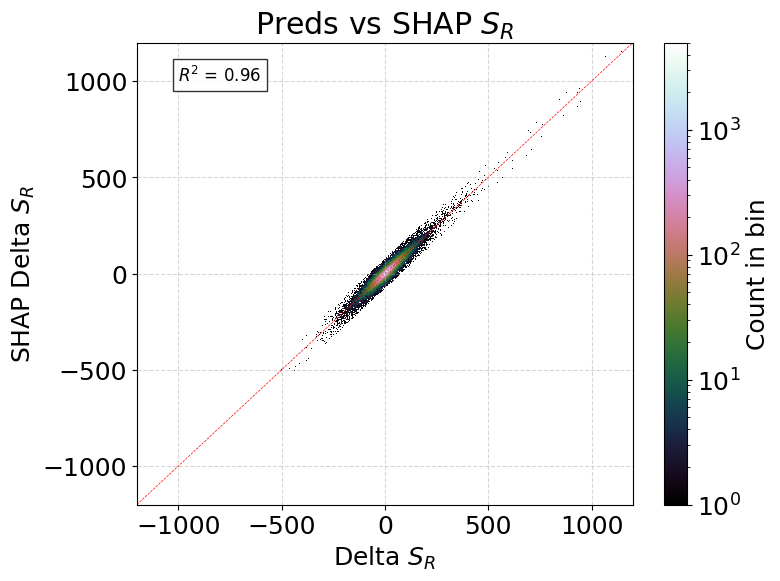

In [11]:
"""
sr_clim_1901_1930_LU_PI = preds.sel(climate='1901_1930', lu='pre-industrial').sr_k6_mean
sr_clim_1901_1930_LU_1991_2020 = preds.sel(climate='1901_1930', lu='1991_2020').sr_k6_mean
sr_clim_1901_1930_LU_1901_1930 = preds.sel(climate='1901_1930', lu='1901_1930').sr_k6_mean
sr_clim_1991_2020_LU_PI = preds.sel(climate='1991_2020', lu='pre-industrial').sr_k6_mean
sr_clim_1991_2020_LU_1991_2020 = preds.sel(climate='1991_2020', lu='1991_2020').sr_k6_mean
sr_clim_1991_2020_LU_1901_1930 = preds.sel(climate='1991_2020', lu='1901_1930').sr_k6_mean
sr_clim_1901_1930_LU_Intact = preds.sel(climate='1901_1930', lu='intact').sr_k6_mean
deltaSR_Intact_to_Present = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1901_1930_LU_Intact
deltaSR_Intact_to_PI = sr_clim_1901_1930_LU_PI - sr_clim_1901_1930_LU_Intact
deltaSR = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1901_1930_LU_1901_1930
deltaSR_clim = sr_clim_1991_2020_LU_1901_1930 - sr_clim_1901_1930_LU_1901_1930
deltaSR_LU = sr_clim_1901_1930_LU_1991_2020 - sr_clim_1901_1930_LU_1901_1930
deltaSR_interaction = deltaSR - deltaSR_clim - deltaSR_LU
"""

scenario_A = {'clim':"1961_1990", 'lu': "1961_1990"} # From
scenario_B = {'clim':"1991_2020", 'lu': "1991_2020"} # To

sr_clim_A_LU_A = preds.sel(climate=scenario_A['clim'], lu=scenario_A['lu']).sr_k6_mean
sr_clim_A_LU_B = preds.sel(climate=scenario_A['clim'], lu=scenario_B['lu']).sr_k6_mean

sr_clim_B_LU_A = preds.sel(climate=scenario_B['clim'], lu=scenario_A['lu']).sr_k6_mean
sr_clim_B_LU_B = preds.sel(climate=scenario_B['clim'], lu=scenario_B['lu']).sr_k6_mean

deltaSR = sr_clim_B_LU_B - sr_clim_A_LU_A
deltaSR_clim = sr_clim_B_LU_A - sr_clim_A_LU_A
deltaSR_LU = sr_clim_A_LU_B - sr_clim_A_LU_A
deltaSR_interaction = deltaSR - deltaSR_clim - deltaSR_LU

pct_deltaSR = deltaSR/sr_clim_A_LU_A * 100
abs_pct_deltaSR = np.abs(pct_deltaSR)

# correlation of deltaSR and SHAPClustered.total_change
# flatten and mask mutually
deltaSR_flat = deltaSR.stack(features=['lat', 'lon'])
SHAPClustered_flat = SHAPClustered.total_change.stack(features=['lat', 'lon'])

# drop nans for correlation calculation
valid_mask = deltaSR_flat.notnull() & SHAPClustered_flat.notnull()
deltaSR_masked = deltaSR_flat.where(valid_mask, drop=True)
SHAP_delta_masked = SHAPClustered_flat.where(valid_mask, drop=True)

# calculate correlation
from scipy.stats import pearsonr
correlation, p_value = pearsonr(deltaSR_masked, SHAP_delta_masked)
print(f"Correlation: {correlation}, p-value: {p_value}")

# predicted vs target as a 2D histogram
from matplotlib.colors import LogNorm
norm = LogNorm(vmin=1, vmax=5000) # log scale for better visibility of dense areas

plt.rcParams['font.size'] = 18
plt.figure(figsize=(8, 6))
plt.hist2d(deltaSR_masked, SHAP_delta_masked, bins=5000, cmap='cubehelix', norm=norm) # log scale for better visibility
plt.colorbar(label='Count in bin')
plt.xlabel('Delta $S_R$')
plt.ylabel('SHAP Delta $S_R$')
plt.title('Preds vs SHAP $S_R$')
plt.plot([-1200, 1200], [-1200, 1200], 'r--', linewidth=0.5) # 1:1 line for reference
# annotate R2 on the plot
plt.text(-1000, 1000, f'$R^2$ = {correlation:.2f}', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.xlim(-1200, 1200)
plt.ylim(-1200, 1200)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [12]:
shap_mm.shap_change_mm.groupby('feature').mean(dim=['lat', 'lon']).to_dataframe().sort_values(by='shap_change_mm', ascending=True)

,shap_change_mm
feature,
temp_wettest_quarter,-0.382397
rain_frac,-0.372055
forest_age,-0.215325
tmean_p75,-0.146577
monthly_tmean_range,-0.138807
precip_coldest_quarter,-0.133817
irr_frac,-0.105714
precip_warmest_quarter,-0.093665
precip_p50,-0.085287


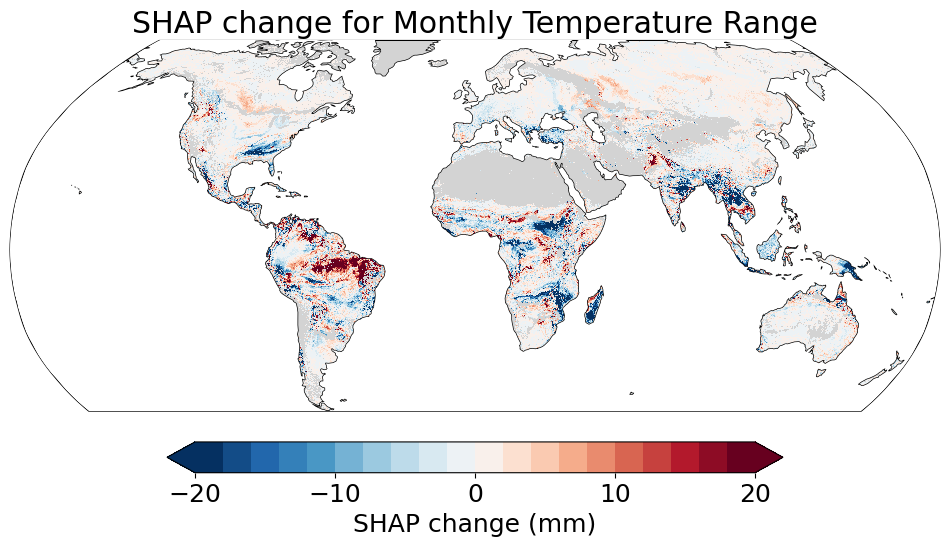

In [9]:
plot_map(shap_mm.shap_change_mm.sel(feature='monthly_tmean_range'),
         vmin=-20, vmax=20, cmap='RdBu_r', discrete_cmap=20,
         cbar_label='SHAP change (mm)', title='SHAP change for Monthly Temperature Range')

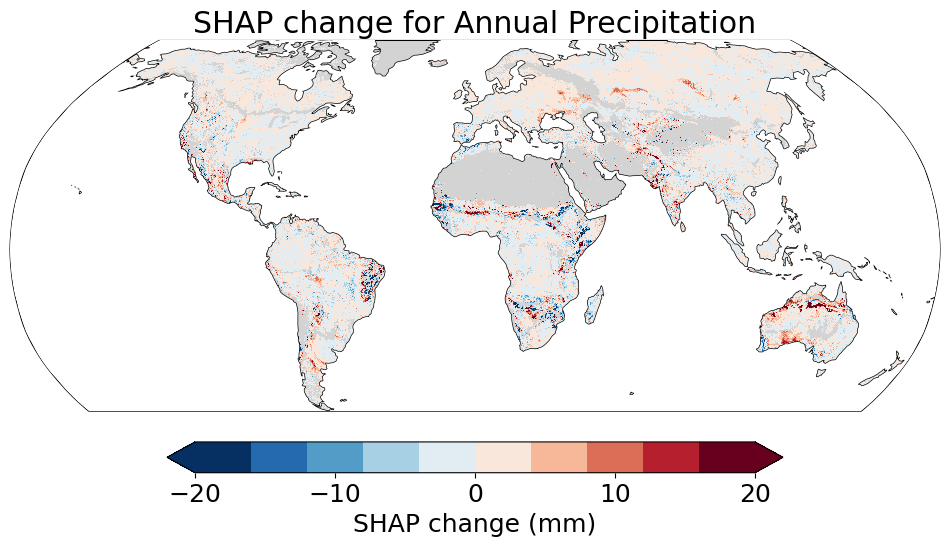

In [10]:
plot_map(shap_mm.shap_change_mm.sel(feature='annual_precip'),
         vmin=-20, vmax=20, cmap='RdBu_r', discrete_cmap=10,
         cbar_label='SHAP change (mm)', title='SHAP change for Annual Precipitation')

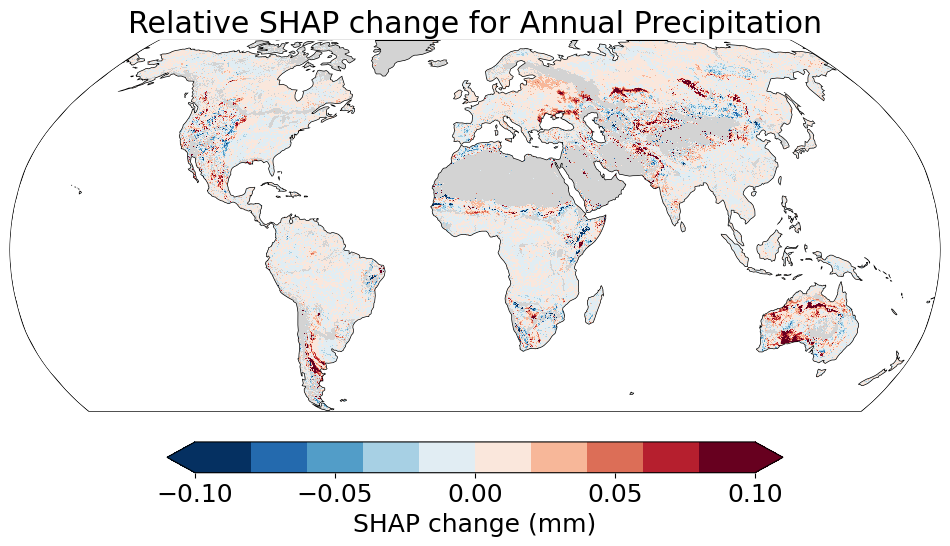

In [11]:
plot_map(shap_mm.shap_change_mm.sel(feature='annual_precip')/shap_mm.pred_A,
         vmin=-0.1, vmax=0.1, cmap='RdBu_r', discrete_cmap=10, cbar_label='SHAP change (mm)', title='Relative SHAP change for Annual Precipitation')

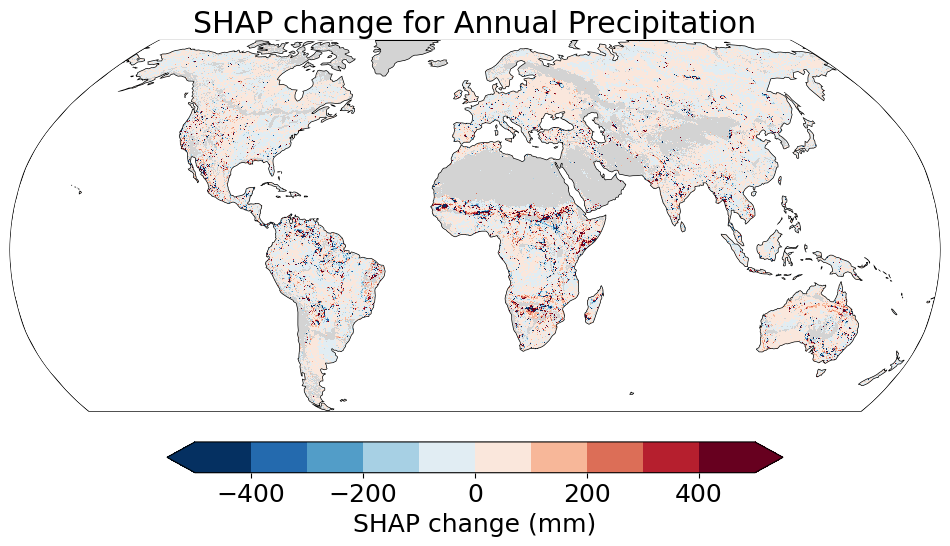

In [12]:
plot_map(shap_mm.shap_change_mm.sel(feature='annual_precip')/((featClim_1991_2020['annual_precip']-featClim_1901_1930['annual_precip'])/featClim_1901_1930['annual_precip']),
         vmin=-500, vmax=500, cmap='RdBu_r', discrete_cmap=10, cbar_label='SHAP change (mm)', title='SHAP change for Annual Precipitation')

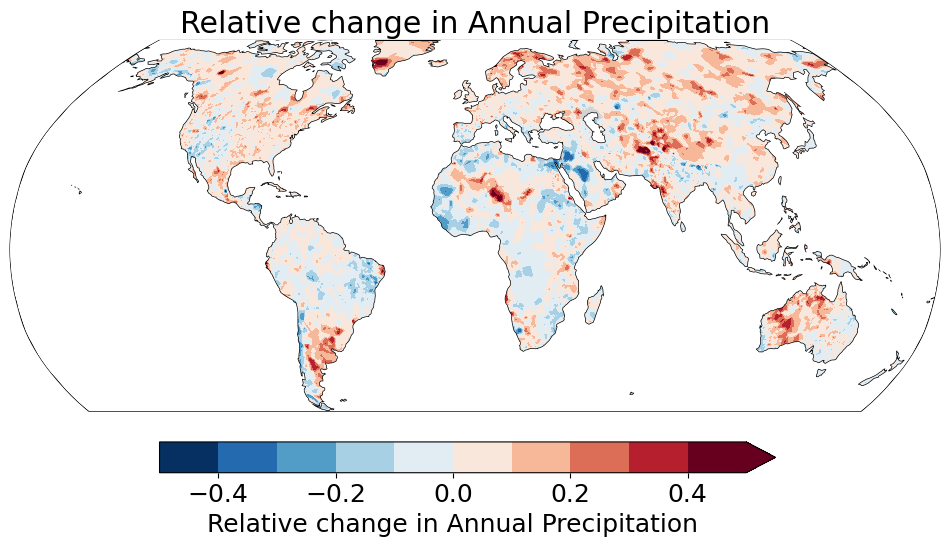

In [13]:
plot_map(((featClim_1991_2020['annual_precip']-featClim_1901_1930['annual_precip'])/featClim_1901_1930['annual_precip']),
         vmin=-0.5, vmax=0.5, cmap='RdBu_r', discrete_cmap=10, cbar_label='Relative change in Annual Precipitation', title='Relative change in Annual Precipitation')

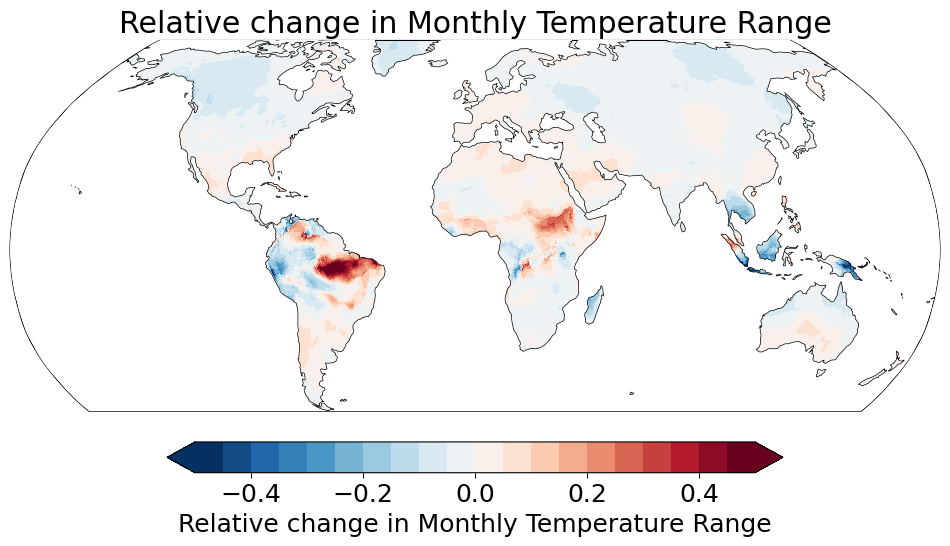

In [14]:
plot_map(((featClim_1991_2020['monthly_tmean_range']-featClim_1901_1930['monthly_tmean_range'])/featClim_1901_1930['monthly_tmean_range']),
         vmin=-0.5, vmax=0.5, cmap='RdBu_r', discrete_cmap=20, cbar_label='Relative change in Monthly Temperature Range', title='Relative change in Monthly Temperature Range')

In [68]:
# SudanFloodedGrassland. lat 6.6 to 8.6, lon 31.8 to 32.8
sudanFloodedGrassland = shap_mm.sel(lat=slice(6.6, 8.6), lon=slice(31.8, 32.8))
LKA_dryzone_paddy = shap_mm.sel(lat=slice(8.32, 8.72), lon=slice(80.32, 80.72))
WA_agriculture = shap_mm.sel(lat=slice(-33.4, -32.4), lon=slice(117.2, 118.2))
Congo_central = shap_mm.sel(lat=slice(-1.5, 1.5), lon=slice(21, 24))
Congo_north = shap_mm.sel(lat=slice(3,6), lon=slice(23.5, 26.5))
Sudd = shap_mm.sel(lat=slice(6, 9), lon=slice(31.5, 34.5))
WestAfrica = shap_mm.sel(lat=slice(7.5, 10.5), lon=slice(-6, -3))
SouthMadagascar = shap_mm.sel(lat=slice(-23.8, -20.8), lon=slice(44.2, 47.2))
LKA_wet = shap_mm.sel(lat=slice(6.94, 7.10), lon=slice(80.15, 80.25))
LKA = shap_mm.sel(lat=slice(5.9, 9.9), lon=slice(79.5, 82))
                      
roi = LKA

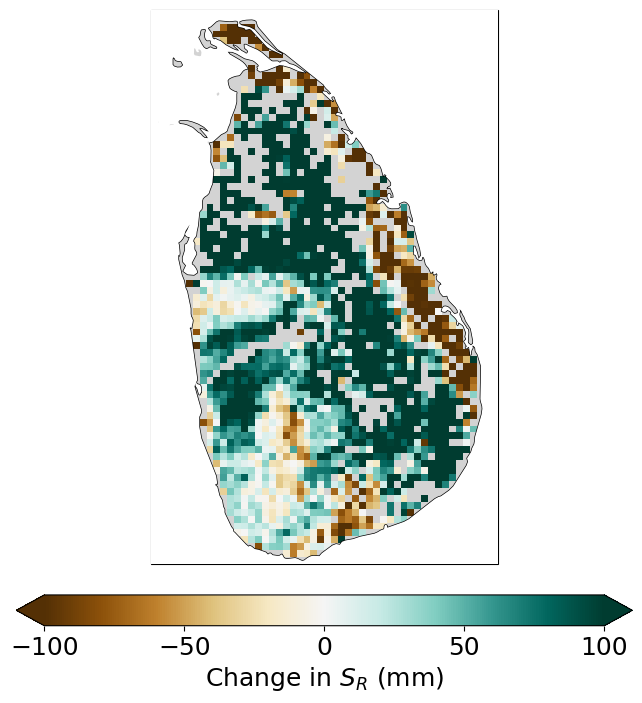

In [69]:
plot_map(roi.total_change, vmin = -100, vmax = 100, cmap='BrBG', cbar_label='Change in $S_R$ (mm)', local_map=True)

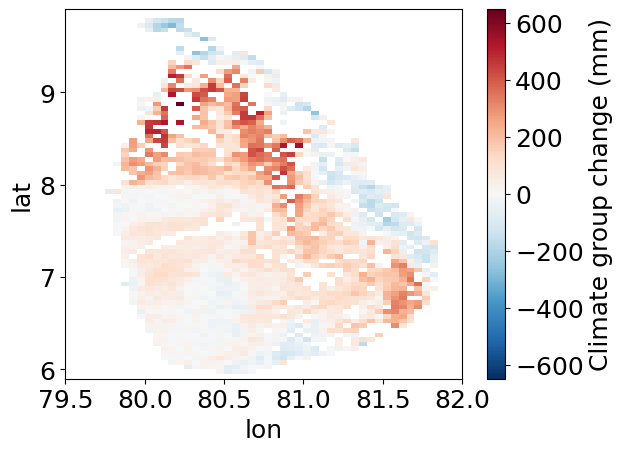

In [71]:
roi.group_climate_mm.plot()

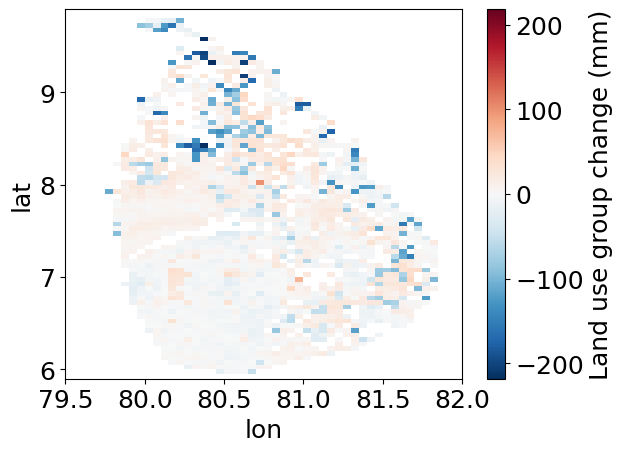

In [72]:
roi.group_lu_mm.plot()

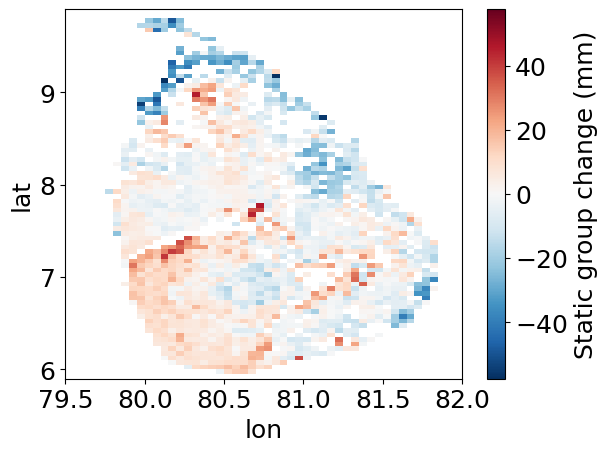

In [73]:
roi.group_static_mm.plot()

In [74]:
roi_shap_change = roi.shap_change_mm.groupby('feature').mean(dim=['lat', 'lon']).to_dataframe().sort_values(by='shap_change_mm', ascending=True)

In [75]:
roi_clim_A = featClim_1961_1990.sel(lat=roi.lat, lon=roi.lon).where(np.isfinite(roi.total_change))
roi_clim_B = featClim_1991_2020.sel(lat=roi.lat, lon=roi.lon).where(np.isfinite(roi.total_change))
roi_lu_A = featLU_1961_1990.sel(lat=roi.lat, lon=roi.lon).where(np.isfinite(roi.total_change))
roi_lu_B = featLU_1991_2020.sel(lat=roi.lat, lon=roi.lon).where(np.isfinite(roi.total_change))
roi_static = featStatic.sel(lat=roi.lat, lon=roi.lon).where(np.isfinite(roi.total_change))

In [76]:
# get means of feature variables to a df
# first convert the features to a dim where coords are the feature names, then take the mean over lat and lon, then convert to a dataframe
roi_clim_1901_1930_ = roi_clim_A.to_array(dim='feature')
roi_clim_1901_1930 = roi_clim_1901_1930_.mean(dim=['lat', 'lon'])
roi_clim_1901_1930.name = '1901_1930'
roi_clim_1901_1930_df = roi_clim_1901_1930.to_dataframe()
roi_clim_1901_1930_df['type'] = 'climate'

roi_clim_1991_2020_ = roi_clim_B.to_array(dim='feature')
roi_clim_1991_2020 = roi_clim_1991_2020_.mean(dim=['lat', 'lon'])
roi_clim_1991_2020.name = '1991_2020'
roi_clim_1991_2020_df = roi_clim_1991_2020.to_dataframe()

roi_lu_1901_1930_ = roi_lu_A.to_array(dim='feature')
roi_lu_1901_1930 = roi_lu_1901_1930_.mean(dim=['lat', 'lon'])
roi_lu_1901_1930.name = '1901_1930'
roi_lu_1901_1930_df = roi_lu_1901_1930.to_dataframe()
roi_lu_1901_1930_df['type'] = 'land_use'

roi_lu_1991_2020_ = roi_lu_B.to_array(dim='feature')
roi_lu_1991_2020 = roi_lu_1991_2020_.mean(dim=['lat', 'lon'])
roi_lu_1991_2020.name = '1991_2020'
roi_lu_1991_2020_df = roi_lu_1991_2020.to_dataframe()

roi_static = roi_static.to_array(dim='feature')
roi_static = roi_static.mean(dim=['lat', 'lon'])
roi_static.name = 'static'
roi_static_df = roi_static.to_dataframe()
roi_static_df['type'] = 'static'

# create to feature df for 1901_1930 and 1991_2020 by concatenating the above dfs
roi_features_1901_1930_df = pd.concat([roi_clim_1901_1930_df, roi_lu_1901_1930_df, roi_static_df.rename(columns={'static': '1901_1930'})], axis=0)
roi_features_1991_2020_df = pd.concat([roi_clim_1991_2020_df, roi_lu_1991_2020_df, roi_static_df['static'].rename('1991_2020')], axis=0)

# concat with roi_shap_change to get a final df with feature, 1901_1930, 1991_2020, and shap_change_mm
roi_shap = roi_shap_change.merge(roi_features_1901_1930_df, left_index=True, right_index=True).merge(roi_features_1991_2020_df, left_index=True, right_index=True)

# orhanize the columns
roi_shap = roi_shap[['type', '1901_1930', '1991_2020', 'shap_change_mm']]
roi_shap = roi_shap.sort_values(by='shap_change_mm', ascending=True).sort_values(by='type', ascending=True)

In [77]:
roi_shap['feature_change_pct'] = (roi_shap['1991_2020'] - roi_shap['1901_1930']) / roi_shap['1901_1930'] * 100
#roi_shap['shap_fraction'] = roi_shap['shap_change_mm'] / roi_shap['shap_change_mm'].sum()
roi_shap = roi_shap.sort_values(by='feature_change_pct', ascending=True).sort_values(by='type', ascending=True)

# replace nan values in feature_change_pct with 0, and also replace inf values with 100
#roi_shap['feature_change_pct'] = roi_shap['feature_change_pct'].fillna(0)
#roi_shap['feature_change_pct'] = roi_shap['feature_change_pct'].replace([np.inf, -np.inf], 100)

# make feature a column instead of index
roi_shap = roi_shap.reset_index().rename(columns={'index': 'feature'})

In [78]:
roi_shap.sort_values(by='shap_change_mm', ascending=True).sort_values(by='type', ascending=True)

,feature,type,1901_1930,1991_2020,shap_change_mm,feature_change_pct
16,tmean_p75,climate,26.877978,27.427870,-2.798286,2.045882
30,min_monthly_precip,climate,50.794386,52.669643,-2.600004,3.691861
32,precip_coldest_quarter,climate,567.106322,603.203690,-2.000498,6.365185
5,precip_p5,climate,62.039538,58.773225,-1.803113,-5.264890
24,tmean_p5,climate,24.339244,24.942341,-0.991129,2.477880
29,gdm_10,climate,191.837628,198.522616,-0.933348,3.484712
14,tmean_p90,climate,27.224876,27.730854,-0.766750,1.858515
9,tmean_iqr,climate,1.890316,1.862469,-0.094156,-1.473185
38,months_gt_30C,climate,0.000000,0.046091,-0.008300,inf
39,frost_months,climate,0.000000,0.000000,0.000084,NaN


In [79]:
# subset top 5 absolute SHAP contributors
top5_shap = roi_shap.reindex(roi_shap.shap_change_mm.abs().sort_values(ascending=False).index).head(5)

In [80]:
top5_shap

,feature,type,1901_1930,1991_2020,shap_change_mm,feature_change_pct
37,precip_deficit_annual,climate,479.772702,583.870176,12.366409,21.697248
33,precip_cv,climate,0.588445,0.628824,11.221228,6.862032
1,precip_p10,climate,73.061666,65.363339,9.644871,-10.536753
25,min_monthly_tmean,climate,24.228590,24.869263,8.942831,2.644283
17,tmean_p50,climate,26.237602,26.784098,6.837723,2.082875


In [147]:
# reset sns style to default
import seaborn as sns
sns.reset_orig()

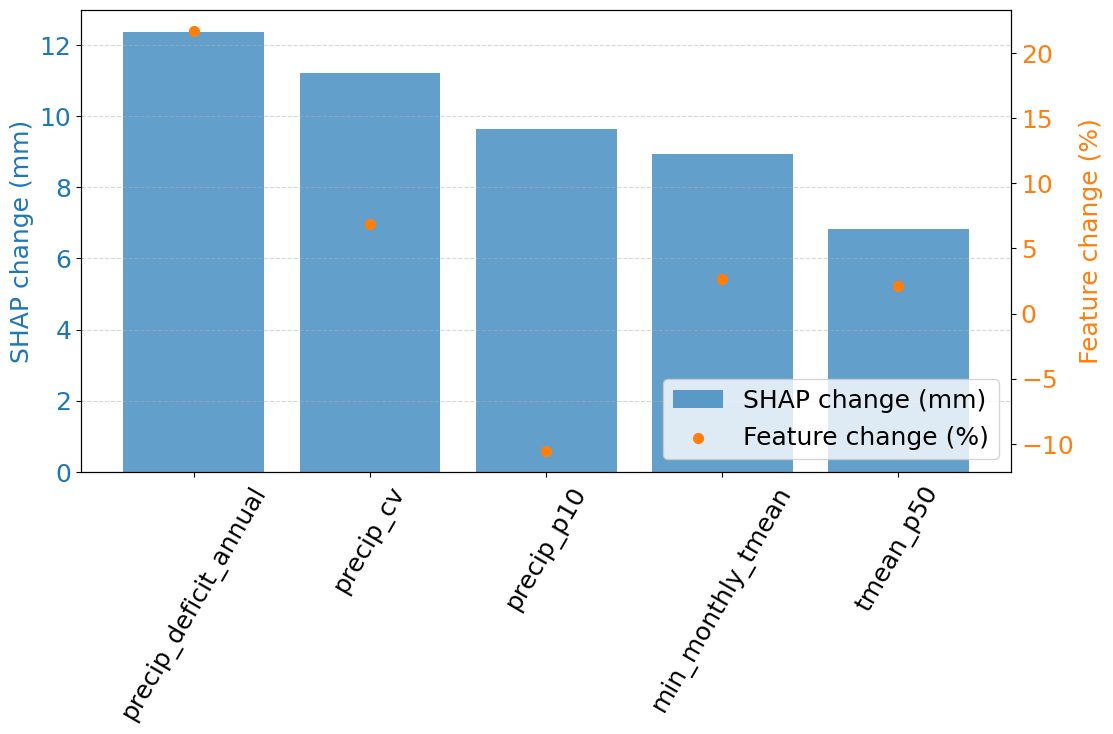

In [81]:
# plot top 5 SHAP and feature change percentage
# on left y-axis, plot SHAP change in mm as a bar plot, and on right y-axis, plot feature change percentage as scatter plot.
# Use different colors for the two y-axes. Use the feature names as x-ticks.

plt.figure(figsize=(12, 6))
# left y-axis. color the bars by type of feature (climate, land_use, static)
ax1 = plt.gca()
ax1.bar(top5_shap['feature'], top5_shap['shap_change_mm'], color='tab:blue', alpha=0.7, label='SHAP change (mm)')
ax1.set_ylabel('SHAP change (mm)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
# rotate x-ticks for better visibility
plt.xticks(rotation=60)
# right y-axis
ax2 = ax1.twinx()
ax2.scatter(top5_shap['feature'], top5_shap['feature_change_pct'], color='tab:orange', marker='o', s=50, label='Feature change (%)')
ax2.set_ylabel('Feature change (%)', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')
# title and grid
#plt.title('Top 5 SHAP Contributors and Feature Change Percentage')
ax1.grid(axis='y', linestyle='--', alpha=0.5)
# legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower right')
plt.show()


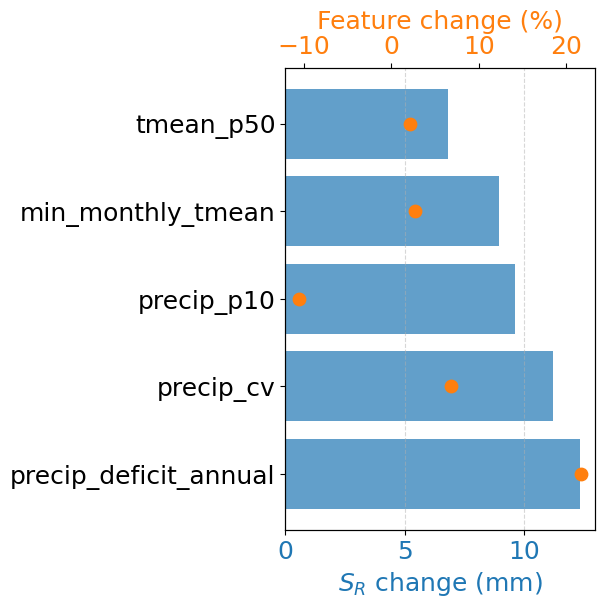

In [82]:
# plot top 5 SHAP and feature change percentage: Transformed version
# features on vertical, on top horizontal: SHAP change in mm as a bar plot, and on bottom horizontal: feature change percentage as scatter plot.
plt.figure(figsize=(4, 6))
# top horizontal: SHAP change in mm as a bar plot
ax1 = plt.gca()
ax1.barh(top5_shap['feature'], top5_shap['shap_change_mm'], color='tab:blue', alpha=0.7, label='SHAP change (mm)')
ax1.set_xlabel('$S_R$ change (mm)', color='tab:blue')
ax1.tick_params(axis='x', labelcolor='tab:blue')
# bottom horizontal: feature change percentage as scatter plot
ax2 = ax1.twiny()
ax2.scatter(top5_shap['feature_change_pct'], top5_shap['feature'], color='tab:orange', marker='o', s=80, label='Feature change (%)')
ax2.set_xlabel('Feature change (%)', color='tab:orange')
ax2.tick_params(axis='x', labelcolor='tab:orange')
# title and grid
#plt.title('Top 5 SHAP Contributors and Feature Change Percentage')
ax1.grid(axis='x', linestyle='--', alpha=0.5)
# legend
#lines_1, labels_1 = ax1.get_legend_handles_labels()
#lines_2, labels_2 = ax2.get_legend_handles_labels()
#ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower right')
plt.show()


/home/vajira/SRchange/.venv/lib/python3.12/site-packages/matplotlib/transforms.py:2437: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


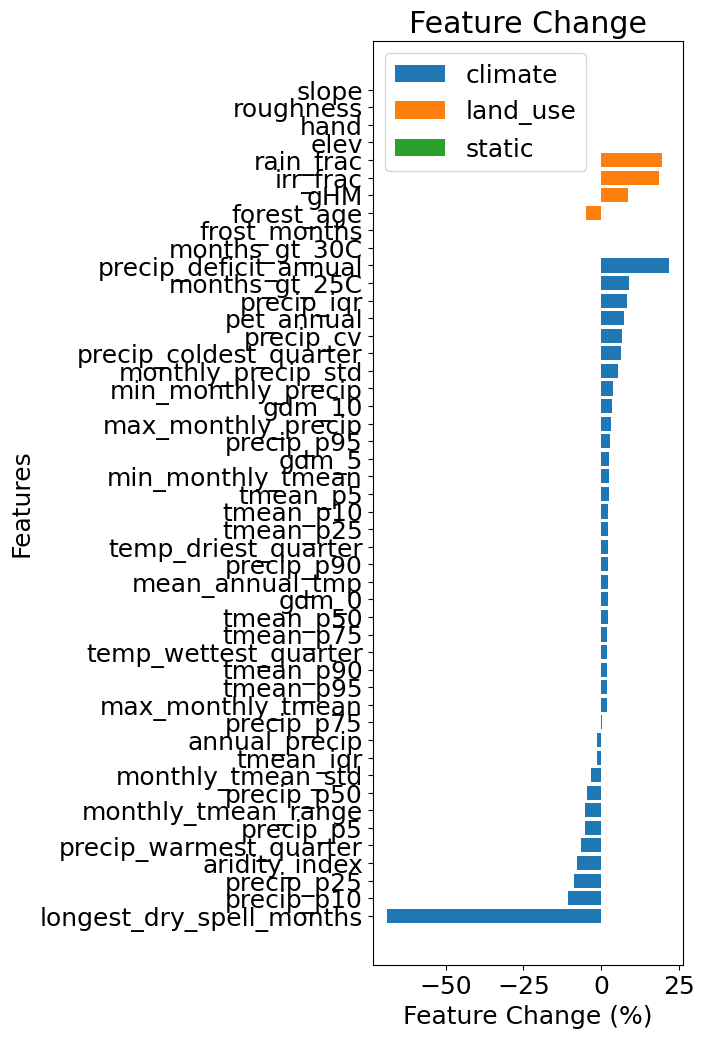

In [83]:
# using roi_shap, plot the feature change and resulting SHAP change in a bar plot, with features on the y-axis and change on the x-axis, colored by type (climate, land_use, static)
import matplotlib.pyplot as plt

plt.figure(figsize=(4,12))
for t in roi_shap['type'].unique():
    data = roi_shap[roi_shap['type'] == t]
    plt.barh(data['feature'], data['feature_change_pct'], label=t)
plt.xlabel('Feature Change (%)')
plt.ylabel('Features')
plt.title('Feature Change')
plt.legend()
plt.show()

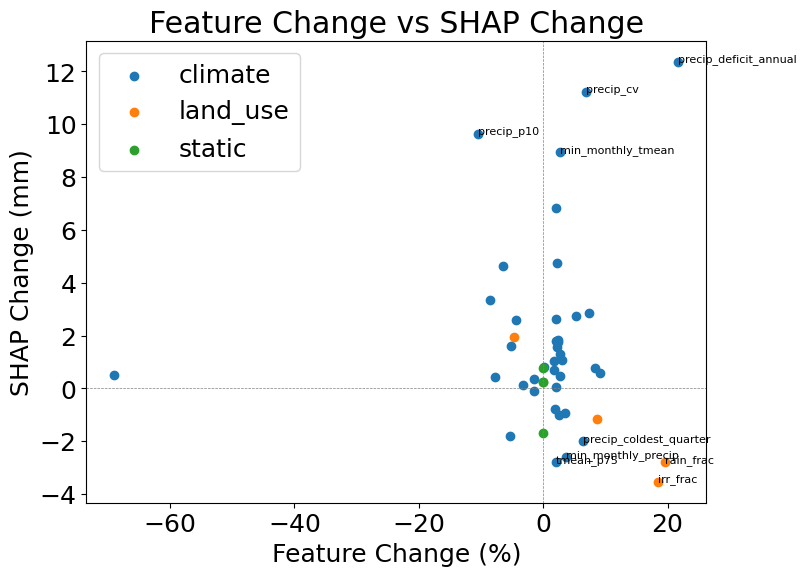

In [84]:
# plot feature change vs SHAP change in a scatter plot, with feature change on the x-axis and SHAP change on the y-axis, colored by type (climate, land_use, static)
plt.figure(figsize=(8,6))

# where shap change < -6 or shap change > 2, show feature name next to each point
for i, row in roi_shap.iterrows():
    if row['shap_change_mm'] < -2 or row['shap_change_mm'] > 8:
        plt.text(row['feature_change_pct'], row['shap_change_mm'], row['feature'], fontsize=8)

for t in roi_shap['type'].unique():
    data = roi_shap[roi_shap['type'] == t]
    plt.scatter(data['feature_change_pct'], data['shap_change_mm'], label=t)

plt.xlabel('Feature Change (%)')
plt.ylabel('SHAP Change (mm)')
plt.title('Feature Change vs SHAP Change')
plt.axhline(0, color='grey', linestyle='--', linewidth=0.5)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.5)
plt.legend()

In [85]:
# alternatively, scatter plot with more flexible label positioning using plotly express,
# with feature change on the x-axis and SHAP change on the y-axis, colored by type (climate, land_use, static)

# clear plotly express figure
fig = None

import plotly.express as px
fig = px.scatter(roi_shap, x='feature_change_pct', y='shap_change_mm', color='type', labels={'feature': 'Feature'}, title='Feature Change vs SHAP Change', hover_data=['feature'])
fig.update_traces(textposition='top center')
fig.update_layout(legend_title_text='Feature Type')
fig.show()

In [90]:
roi

<xarray.Dataset> Size: 870kB
Dimensions:           (lat: 80, lon: 50, feature: 48)
Coordinates:
  * lat               (lat) float64 640B 5.925 5.975 6.025 ... 9.775 9.825 9.875
  * lon               (lon) float64 400B 79.53 79.58 79.62 ... 81.88 81.92 81.97
  * feature           (feature) <U24 5kB 'elev' 'slope' ... 'forest_age'
Data variables:
    pred_A            (lat, lon) float32 16kB nan nan nan nan ... nan nan nan
    pred_B            (lat, lon) float32 16kB nan nan nan nan ... nan nan nan
    total_change      (lat, lon) float32 16kB nan nan nan nan ... nan nan nan
    shap_change_mm    (lat, lon, feature) float32 768kB nan nan nan ... nan nan
    group_climate_mm  (lat, lon) float32 16kB nan nan nan nan ... nan nan nan
    group_lu_mm       (lat, lon) float32 16kB nan nan nan nan ... nan nan nan
    group_static_mm   (lat, lon) float32 16kB nan nan nan nan ... nan nan nan

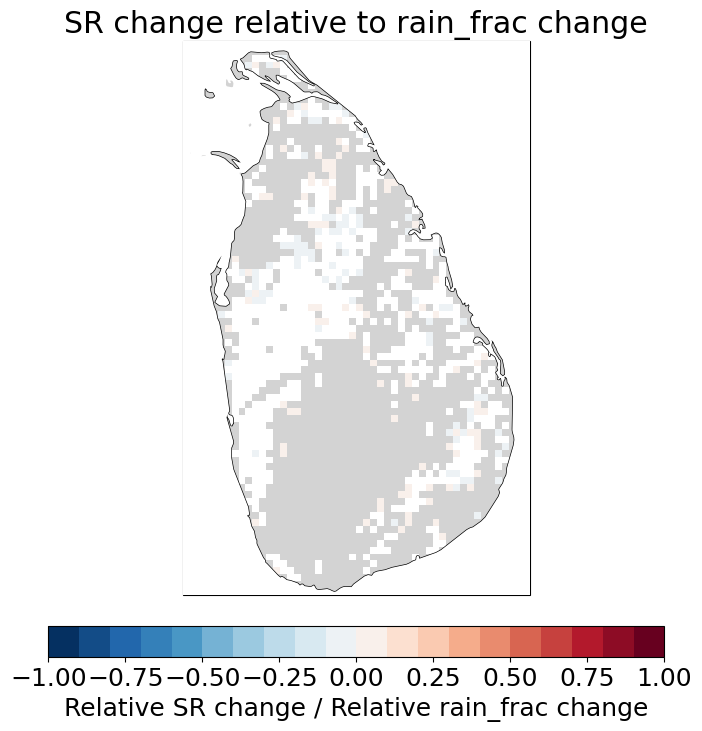

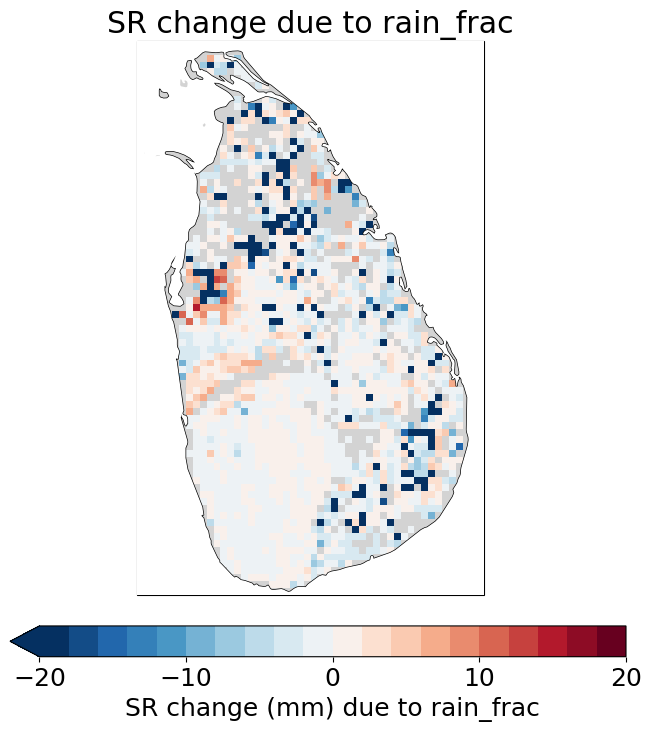

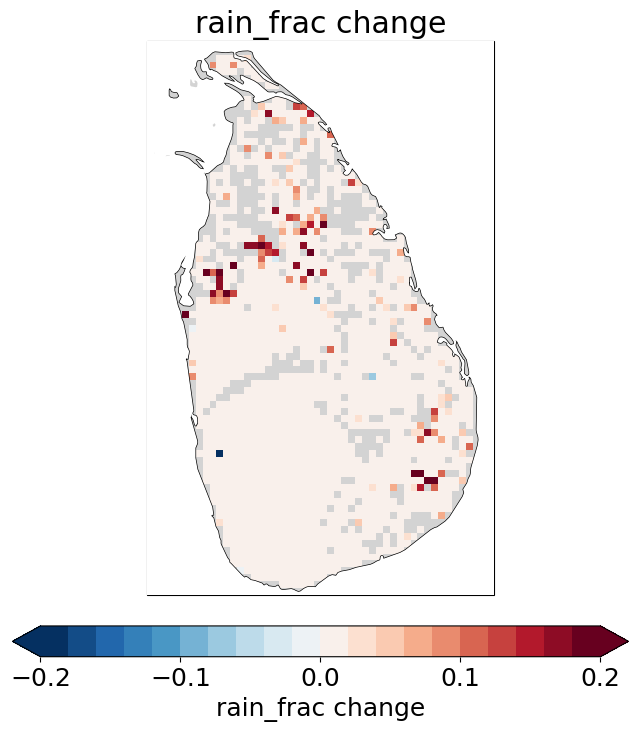

In [115]:
feature_to_map = 'rain_frac'
roi_feature_change = (roi_lu_B[feature_to_map] - roi_lu_A[feature_to_map])
roi_feature_rel_change = roi_feature_change / roi_lu_A[feature_to_map]
roi_feature_shap = roi.shap_change_mm.sel(feature=feature_to_map)
roi_feature_shap_rel = roi_feature_shap/roi.pred_A
roi_feature_shap_rel_change = roi_feature_shap_rel / roi_feature_rel_change
# plot relative SHAP change vs relative feature change for the selected feature
plot_map(roi_feature_shap_rel_change, vmin = -1, vmax = 1, cmap='RdBu_r',
         discrete_cmap=20,
         cbar_label=f'Relative SR change / Relative {feature_to_map} change',
         title=f'SR change relative to {feature_to_map} change',
         local_map=True)
# plot SHAP
plot_map(roi_feature_shap, vmin = -20, vmax = 20, cmap='RdBu_r',
         discrete_cmap=20,
         cbar_label=f'SR change (mm) due to {feature_to_map}',
         title=f'SR change due to {feature_to_map}',
         local_map=True)
# map feature change
plot_map(roi_feature_change, vmin = -0.2, vmax = 0.2, cmap='RdBu_r',
         discrete_cmap=20,
         cbar_label=f'{feature_to_map} change',
         title=f'{feature_to_map} change',
         local_map=True)